# Review 2 — Clustering Comparison

Consolidated comparison of K-Means and Agglomerative linkage variants using the three mandatory internal metrics.

## 1. Load metric results

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "Online Retail.xlsx").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not locate project root containing data/Online Retail.xlsx")
    ROOT = ROOT.parent
R = ROOT / "results" / "clustering"
F = ROOT / "figures" / "clustering"
R.mkdir(parents=True, exist_ok=True)
F.mkdir(parents=True, exist_ok=True)
paths = [R / "kmeans_metrics.csv", R / "agglomerative_linkage_comparison.csv"]
missing = [str(p) for p in paths if not p.is_file()]
if missing:
    raise FileNotFoundError("Run both clustering notebooks first. Missing: " + ", ".join(missing))
frames = [pd.read_csv(p) for p in paths]
comparison = pd.concat(frames, ignore_index=True, sort=False)
display(comparison.round(4))
comparison.to_csv(R / "clustering_comparison.csv", index=False)


,algorithm,n_clusters,silhouette,davies_bouldin,calinski_harabasz,linkage
0,K-Means,4,0.3445,0.9254,3780.6716,NaN
1,Agglomerative (ward),4,0.3106,0.9885,3408.3823,ward
2,Agglomerative (complete),4,0.2701,0.8973,1721.1058,complete
3,Agglomerative (average),4,0.3303,0.6893,77.2785,average


## 2. Compare each required metric

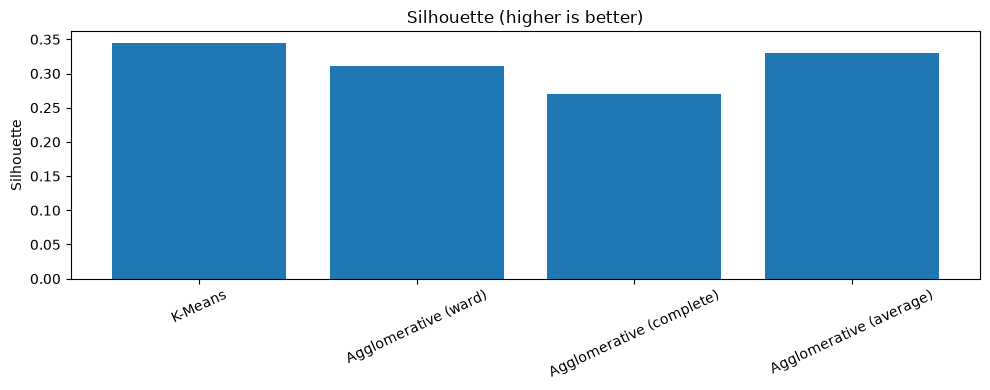

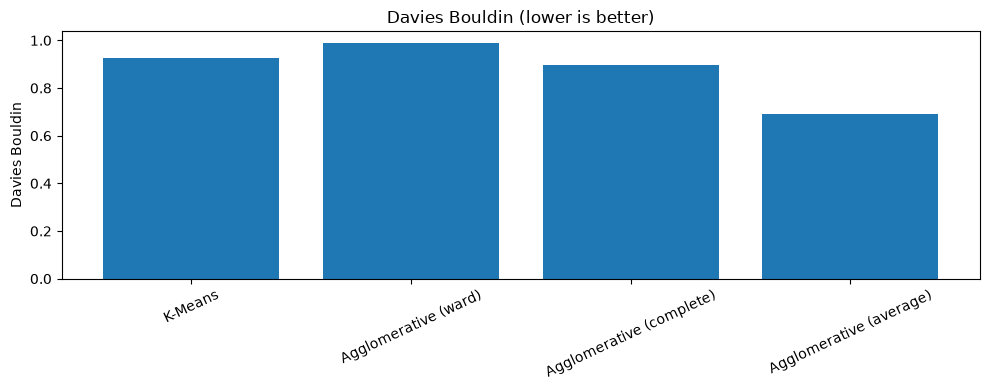

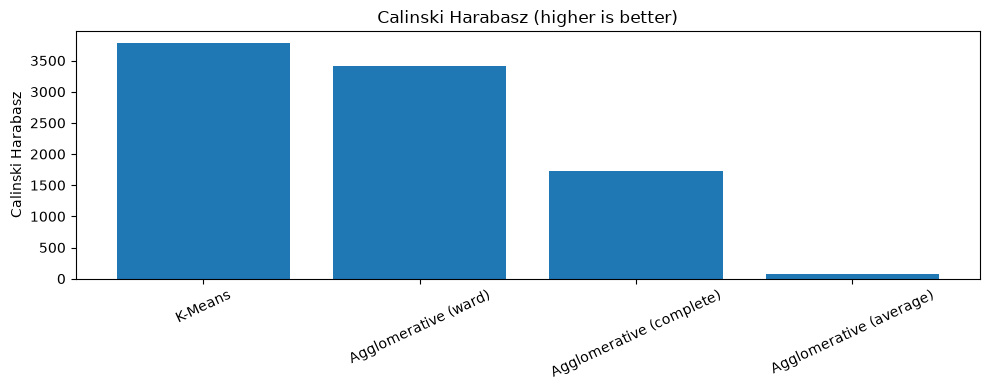

In [2]:
for metric, direction in [("silhouette", "higher is better"), ("davies_bouldin", "lower is better"), ("calinski_harabasz", "higher is better")]:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(comparison["algorithm"], comparison[metric])
    ax.set_title(metric.replace("_", " ").title() + " (" + direction + ")")
    ax.set_ylabel(metric.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    fig.savefig(F / ("comparison_" + metric + ".png"), dpi=150)
    plt.show()
